In [ ]:
# ============================================================
# GYM PREDICTIVE ANALYTICS PROJECT
# Predicting Calories Burned Using Machine Learning
# Dataset: Gym Members Exercise Tracking
# ============================================================

# STEP 1: IMPORT LIBRARIES

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
import joblib

In [ ]:
# ============================================================
# STEP 2: LOAD THE ALREADY DOWNLOADED DATASET
# ============================================================

file_path = "/content/gym_members_exercise_tracking.csv"

if not os.path.exists(file_path):
    raise FileNotFoundError(
        "Dataset not found. Upload gym_members_exercise_tracking.csv "
        "to the Files panel in Google Colab."
    )

df = pd.read_csv(file_path)

print("\nDataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five records:")
display(df.head())


# ============================================================
# STEP 3: DATA INSPECTION
# ============================================================

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

print("\nMissing values before cleaning:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows before cleaning:", df.duplicated().sum())


Dataset loaded successfully!
Dataset shape: (973, 15)

Column names:
['Age', 'Gender', 'Weight (kg)', 'Height (m)', 'Max_BPM', 'Avg_BPM', 'Resting_BPM', 'Session_Duration (hours)', 'Calories_Burned', 'Workout_Type', 'Fat_Percentage', 'Water_Intake (liters)', 'Workout_Frequency (days/week)', 'Experience_Level', 'BMI']

First five records:


,Age,Gender,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Workout_Type,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI
0,56,Male,88.3,1.71,180,157,60,1.69,1313.0,Yoga,12.6,3.5,4,3,30.20
1,46,Female,74.9,1.53,179,151,66,1.30,883.0,HIIT,33.9,2.1,4,2,32.00
2,32,Female,68.1,1.66,167,122,54,1.11,677.0,Cardio,33.4,2.3,4,2,24.71
3,25,Male,53.2,1.70,190,164,56,0.59,532.0,Strength,28.8,2.1,3,1,18.41
4,38,Male,46.1,1.79,188,158,68,0.64,556.0,Strength,29.2,2.8,3,1,14.39



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 973 entries, 0 to 972
Data columns (total 15 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Age                            973 non-null    int64  
 1   Gender                         973 non-null    object 
 2   Weight (kg)                    973 non-null    float64
 3   Height (m)                     973 non-null    float64
 4   Max_BPM                        973 non-null    int64  
 5   Avg_BPM                        973 non-null    int64  
 6   Resting_BPM                    973 non-null    int64  
 7   Session_Duration (hours)       973 non-null    float64
 8   Calories_Burned                973 non-null    float64
 9   Workout_Type                   973 non-null    object 
 10  Fat_Percentage                 973 non-null    float64
 11  Water_Intake (liters)          973 non-null    float64
 12  Workout_Frequency (days/week

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,973.0,NaN,NaN,NaN,38.683453,12.180928,18.0,28.0,40.0,49.0,59.0
Gender,973,2,Male,511,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Weight (kg),973.0,NaN,NaN,NaN,73.854676,21.2075,40.0,58.1,70.0,86.0,129.9
Height (m),973.0,NaN,NaN,NaN,1.72258,0.12772,1.5,1.62,1.71,1.8,2.0
Max_BPM,973.0,NaN,NaN,NaN,179.883864,11.525686,160.0,170.0,180.0,190.0,199.0
Avg_BPM,973.0,NaN,NaN,NaN,143.766701,14.345101,120.0,131.0,143.0,156.0,169.0
Resting_BPM,973.0,NaN,NaN,NaN,62.223022,7.32706,50.0,56.0,62.0,68.0,74.0
Session_Duration (hours),973.0,NaN,NaN,NaN,1.256423,0.343033,0.5,1.04,1.26,1.46,2.0
Calories_Burned,973.0,NaN,NaN,NaN,905.422405,272.641516,303.0,720.0,893.0,1076.0,1783.0
Workout_Type,973,4,Strength,258,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing values before cleaning:


,Missing Values
Age,0
Gender,0
Weight (kg),0
Height (m),0
Max_BPM,0
Avg_BPM,0
Resting_BPM,0
Session_Duration (hours),0
Calories_Burned,0
Workout_Type,0



Duplicate rows before cleaning: 0


In [ ]:
# STEP 4: DATA CLEANING


# Remove leading/trailing spaces from column names
df.columns = df.columns.str.strip()

# Remove duplicate records
df = df.drop_duplicates().copy()

# Define the prediction target
target_col = "Calories_Burned"

if target_col not in df.columns:
    raise ValueError(
        f"Target column '{target_col}' was not found. "
        f"Available columns: {df.columns.tolist()}"
    )

# Convert the target to numeric values
df[target_col] = pd.to_numeric(df[target_col], errors="coerce")

# Remove records where the target is missing or invalid
df = df.dropna(subset=[target_col]).copy()

# Remove impossible negative calorie values
df = df[df[target_col] >= 0].copy()

# Convert numeric-looking columns to numeric when appropriate.
# This handles columns that may have been imported as text.
for col in df.columns:
    if col == target_col:
        continue

    if df[col].dtype == "object":
        converted = pd.to_numeric(df[col], errors="coerce")

        # Convert only if most non-missing values are numeric
        original_nonmissing = df[col].notna().sum()
        if original_nonmissing > 0:
            numeric_fraction = converted.notna().sum() / original_nonmissing
            if numeric_fraction >= 0.90:
                df[col] = converted

print("\nDataset shape after cleaning:", df.shape)
print("Duplicate rows after cleaning:", df.duplicated().sum())

print("\nMissing values after basic cleaning:")
display(df.isnull().sum().to_frame("Missing Values"))


Dataset shape after cleaning: (973, 15)
Duplicate rows after cleaning: 0

Missing values after basic cleaning:


,Missing Values
Age,0
Gender,0
Weight (kg),0
Height (m),0
Max_BPM,0
Avg_BPM,0
Resting_BPM,0
Session_Duration (hours),0
Calories_Burned,0
Workout_Type,0


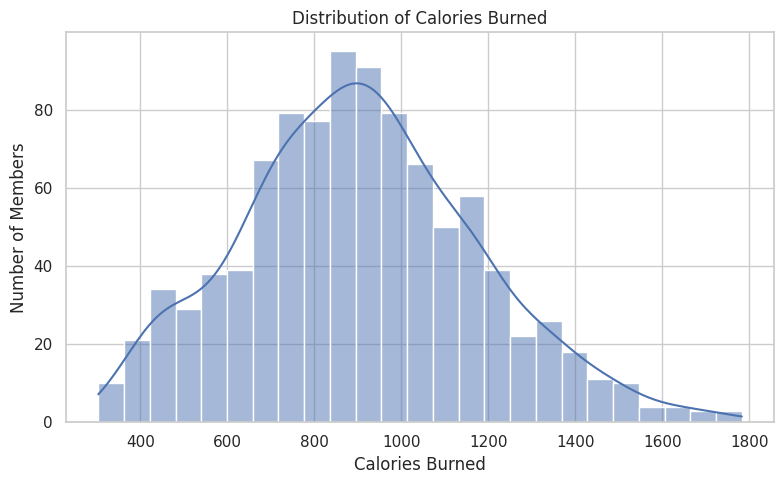


Interpretation of Visualization 1:
This graph shows the distribution of calories burned in the dataset.
The most common calorie ranges indicate the workout outcomes that
occur most frequently. A skewed distribution may indicate that some
sessions burn considerably more calories than others.



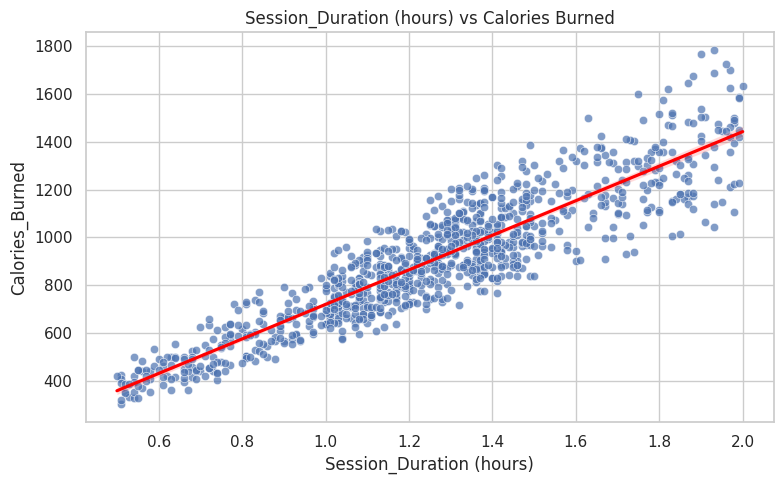


Interpretation of Visualization 2:
This scatter plot examines the relationship between Session_Duration (hours)
and calories burned. An upward trend suggests that longer sessions
are associated with higher calorie expenditure in this dataset.
Association does not by itself prove causation.



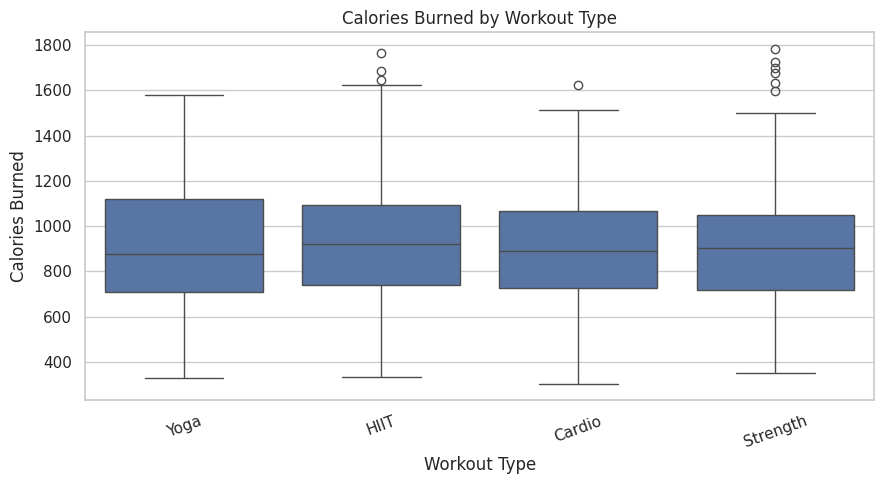


Interpretation of Visualization 3:
The box plot compares calorie expenditure across workout categories.
Differences in medians and spreads suggest that calorie expenditure
varies across workout types. The results describe this dataset and
should not be treated as a guaranteed outcome for every person.



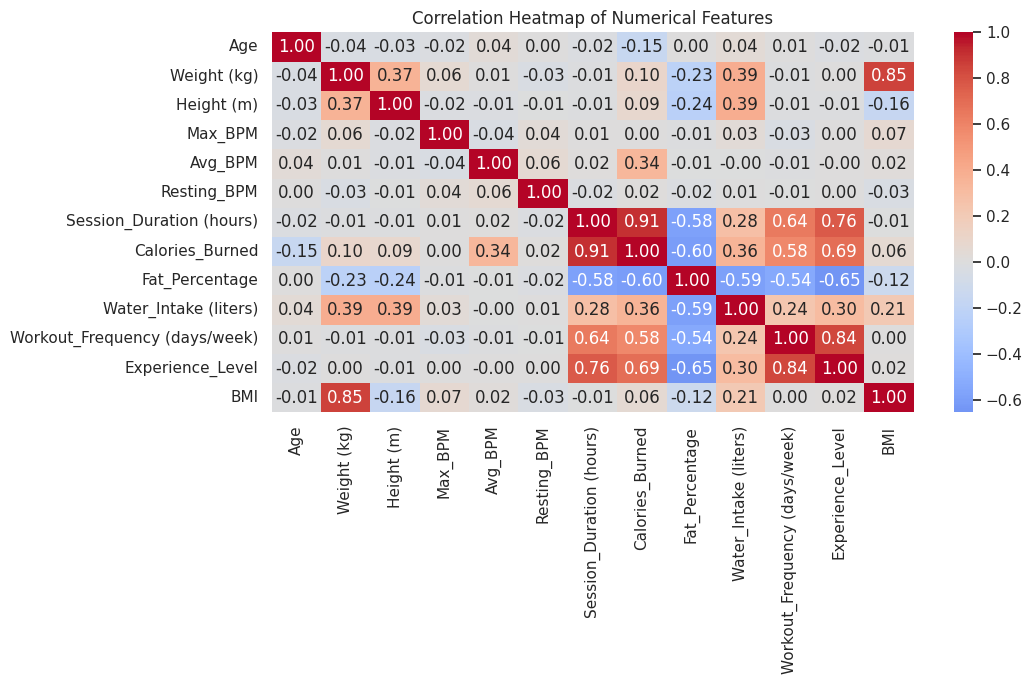


Interpretation of Visualization 4:
The heatmap shows the strength and direction of linear relationships
between numerical variables. Correlation does not prove causation.
Very strongly related features may contain overlapping information.



In [ ]:
# STEP 5: EXPLORATORY DATA ANALYSIS (EDA)


# Visualization 1: Distribution of calories burned
plt.figure(figsize=(8, 5))
sns.histplot(df[target_col], kde=True, bins=25)
plt.title("Distribution of Calories Burned")
plt.xlabel("Calories Burned")
plt.ylabel("Number of Members")
plt.tight_layout()
plt.show()

print("""
Interpretation of Visualization 1:
This graph shows the distribution of calories burned in the dataset.
The most common calorie ranges indicate the workout outcomes that
occur most frequently. A skewed distribution may indicate that some
sessions burn considerably more calories than others.
""")


# Visualization 2: Workout duration vs calories burned
duration_col = "Session_Duration (hours)"

if duration_col in df.columns:
    x_col = duration_col
else:
    duration_candidates = [
        c for c in df.columns
        if "duration" in c.lower() and c != target_col
    ]
    x_col = duration_candidates[0] if duration_candidates else None

if x_col is not None and pd.api.types.is_numeric_dtype(df[x_col]):
    plot_data = df[[x_col, target_col]].dropna()

    plt.figure(figsize=(8, 5))
    sns.scatterplot(data=plot_data, x=x_col, y=target_col, alpha=0.7)
    sns.regplot(
        data=plot_data, x=x_col, y=target_col,
        scatter=False, color="red"
    )
    plt.title(f"{x_col} vs Calories Burned")
    plt.tight_layout()
    plt.show()

    print(f"""
Interpretation of Visualization 2:
This scatter plot examines the relationship between {x_col}
and calories burned. An upward trend suggests that longer sessions
are associated with higher calorie expenditure in this dataset.
Association does not by itself prove causation.
""")
else:
    numeric_candidates = [
        c for c in df.select_dtypes(include=np.number).columns
        if c != target_col
    ]

    if numeric_candidates:
        x_col = numeric_candidates[0]
        plt.figure(figsize=(8, 5))
        sns.scatterplot(data=df, x=x_col, y=target_col, alpha=0.7)
        plt.title(f"{x_col} vs Calories Burned")
        plt.tight_layout()
        plt.show()

        print(f"Interpretation: This plot compares {x_col} with calories burned.")


# Visualization 3: Calories burned by workout type
workout_col = "Workout_Type"

if workout_col in df.columns:
    plt.figure(figsize=(9, 5))
    sns.boxplot(data=df, x=workout_col, y=target_col)
    plt.title("Calories Burned by Workout Type")
    plt.xlabel("Workout Type")
    plt.ylabel("Calories Burned")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

    print("""
Interpretation of Visualization 3:
The box plot compares calorie expenditure across workout categories.
Differences in medians and spreads suggest that calorie expenditure
varies across workout types. The results describe this dataset and
should not be treated as a guaranteed outcome for every person.
""")
else:
    numeric_cols = [
        c for c in df.select_dtypes(include=np.number).columns
        if c != target_col
    ]

    if numeric_cols:
        x_col = numeric_cols[min(1, len(numeric_cols) - 1)]
        plt.figure(figsize=(8, 5))
        sns.scatterplot(data=df, x=x_col, y=target_col, alpha=0.7)
        plt.title(f"{x_col} vs Calories Burned")
        plt.tight_layout()
        plt.show()

        print(f"Interpretation: This plot explores how {x_col} relates to calories burned.")


# Visualization 4: Correlation heatmap for numerical variables
numeric_df = df.select_dtypes(include=np.number)

if numeric_df.shape[1] >= 2:
    plt.figure(figsize=(11, 7))
    sns.heatmap(
        numeric_df.corr(),
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0
    )
    plt.title("Correlation Heatmap of Numerical Features")
    plt.tight_layout()
    plt.show()

    print("""
Interpretation of Visualization 4:
The heatmap shows the strength and direction of linear relationships
between numerical variables. Correlation does not prove causation.
Very strongly related features may contain overlapping information.
""")

In [ ]:
# STEP 7: PREPARE FEATURES AND TARGET


# X contains predictor variables; y contains the value to predict.
X = df.drop(columns=[target_col]).copy()
y = df[target_col].copy()

# Remove columns that have no useful variation.
# This also avoids problems with columns containing only missing values.
constant_cols = [
    col for col in X.columns
    if X[col].nunique(dropna=True) <= 1
]

if constant_cols:
    print("\nRemoving constant columns:", constant_cols)
    X = X.drop(columns=constant_cols)

if X.shape[1] == 0:
    raise ValueError("No usable predictor columns remain after cleaning.")

# Identify numerical and categorical predictors
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("\nNumerical features:", numeric_features)
print("\nCategorical features:", categorical_features)
print("\nFeature matrix shape:", X.shape)
print("Target vector shape:", y.shape)


# STEP 8: TRAIN-TEST SPLIT

# Keep some records separate to evaluate predictions on unseen data.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("\nTraining records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])



Numerical features: ['Age', 'Weight (kg)', 'Height (m)', 'Max_BPM', 'Avg_BPM', 'Resting_BPM', 'Session_Duration (hours)', 'Fat_Percentage', 'Water_Intake (liters)', 'Workout_Frequency (days/week)', 'Experience_Level', 'BMI']

Categorical features: ['Gender', 'Workout_Type']

Feature matrix shape: (973, 14)
Target vector shape: (973,)

Training records: 778
Testing records: 195


In [ ]:
# STEP 9: DATA PREPROCESSING PIPELINE

# Numerical features:
# Fill missing values with the median.
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical features:
# Fill missing values with the most frequent category.
# Convert categories to numeric indicator columns.
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Apply suitable preprocessing to each feature type.
transformers = []

if numeric_features:
    transformers.append(
        ("numeric", numeric_transformer, numeric_features)
    )

if categorical_features:
    transformers.append(
        ("categorical", categorical_transformer, categorical_features)
    )

preprocessor = ColumnTransformer(transformers=transformers)


# STEP 10: BUILD AND TRAIN THE PREDICTIVE MODEL

# Random Forest combines many decision trees to predict a numerical value.
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        random_state=RANDOM_STATE,
        min_samples_leaf=2,
        n_jobs=-1
    ))
])

print("\nTraining Random Forest Regressor...")
model.fit(X_train, y_train)

print("Model training completed successfully!")
import joblib
import os
from google.colab import files

# Save a fresh copy of the successfully loaded model
joblib.dump(model, "/content/gym_calorie_model_fixed.pkl")

print(
    "New file size:",
    os.path.getsize("/content/gym_calorie_model_fixed.pkl"),
    "bytes"
)

files.download("/content/gym_calorie_model_fixed.pkl")



Training Random Forest Regressor...
Model training completed successfully!
New file size: 6211523 bytes


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


MODEL EVALUATION RESULTS
Mean Absolute Error (MAE): 36.75 calories
Root Mean Squared Error (RMSE): 48.95 calories
R-squared (R²): 0.9713

Sample test predictions:


,Actual Calories,Predicted Calories,Absolute Error
0,929.0,922.71,6.29
1,1401.0,1456.70,55.70
2,925.0,892.65,32.35
3,1155.0,1083.54,71.46
4,1587.0,1418.75,168.25
5,1247.0,1378.75,131.75
6,950.0,939.90,10.10
7,927.0,968.01,41.01
8,1053.0,1064.24,11.24
9,1201.0,1131.79,69.21


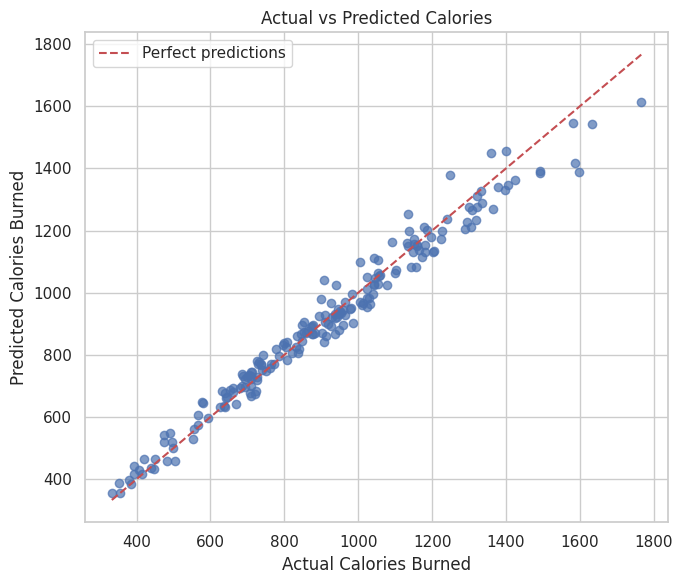

In [ ]:
# STEP 11: MODEL EVALUATION

# Predict values for the unseen test set.
y_pred = model.predict(X_test)

# MAE: average absolute prediction error.
mae = mean_absolute_error(y_test, y_pred)

# RMSE: penalizes large prediction errors more strongly.
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

# R²: compares model performance with predicting the test-set mean.
r2 = r2_score(y_test, y_pred)

print("\n" + "=" * 50)
print("MODEL EVALUATION RESULTS")
print("=" * 50)

print(f"Mean Absolute Error (MAE): {mae:.2f} calories")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f} calories")
print(f"R-squared (R²): {r2:.4f}")


# Compare actual and predicted values.
comparison = pd.DataFrame({
    "Actual Calories": y_test.to_numpy(),
    "Predicted Calories": y_pred
})

comparison["Absolute Error"] = abs(
    comparison["Actual Calories"] - comparison["Predicted Calories"]
)

print("\nSample test predictions:")
display(comparison.head(10).round(2))


# Visualization 5: Actual vs predicted calories
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.7)

min_val = min(float(y_test.min()), float(np.min(y_pred)))
max_val = max(float(y_test.max()), float(np.max(y_pred)))

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    label="Perfect predictions"
)

plt.xlabel("Actual Calories Burned")
plt.ylabel("Predicted Calories Burned")
plt.title("Actual vs Predicted Calories")
plt.legend()
plt.tight_layout()
plt.show()


Top 10 features associated with model predictions:


,Feature,Importance
6,numeric__Session_Duration (hours),0.8362
4,numeric__Avg_BPM,0.1006
0,numeric__Age,0.0193
7,numeric__Fat_Percentage,0.0126
12,categorical__Gender_Female,0.0060
13,categorical__Gender_Male,0.0053
2,numeric__Height (m),0.0045
1,numeric__Weight (kg),0.0037
8,numeric__Water_Intake (liters),0.0029
11,numeric__BMI,0.0027


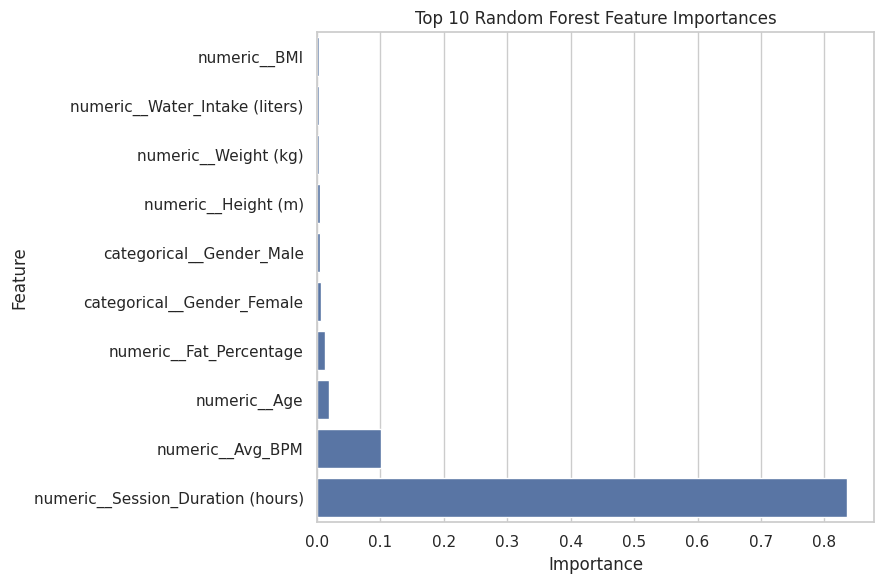


Interpretation:
Features with larger importance values contributed more to the
Random Forest's predictions relative to other features in this model.
Importance does not prove that a feature causes higher calorie burn.



In [ ]:
# STEP 12: FEATURE IMPORTANCE

# Extract feature names after preprocessing.
trained_preprocessor = model.named_steps["preprocessor"]
trained_regressor = model.named_steps["regressor"]

try:
    feature_names = trained_preprocessor.get_feature_names_out()
    importances = trained_regressor.feature_importances_

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    }).sort_values("Importance", ascending=False)

    print("\nTop 10 features associated with model predictions:")
    display(importance_df.head(10).round(4))

    plt.figure(figsize=(9, 6))
    top_features = importance_df.head(10).sort_values("Importance")
    sns.barplot(
        data=top_features,
        x="Importance",
        y="Feature"
    )
    plt.title("Top 10 Random Forest Feature Importances")
    plt.tight_layout()
    plt.show()

    print("""
Interpretation:
Features with larger importance values contributed more to the
Random Forest's predictions relative to other features in this model.
Importance does not prove that a feature causes higher calorie burn.
""")

except Exception as e:
    print("Feature importance could not be displayed:", e)

In [ ]:
# STEP 13: MAKE AT LEAST TWO NEW PREDICTIONS

# Create two example profiles using typical values from the dataset.
# Numeric fields use the training median.
# Categorical fields use the most frequent training category.
# Edit these examples to test other profiles.
new_profiles = {}

for col in X.columns:
    if col in numeric_features:
        new_profiles[col] = [X_train[col].median()] * 2
    else:
        mode_values = X_train[col].mode(dropna=True)
        default_value = mode_values.iloc[0] if not mode_values.empty else "Unknown"
        new_profiles[col] = [default_value] * 2

new_data = pd.DataFrame(new_profiles, columns=X.columns)

# Modify two available numeric fields to make the examples different.
# Values are illustrative and do not guarantee realistic combinations.
if numeric_features:
    first_numeric = numeric_features[0]
    new_data.loc[0, first_numeric] = X_train[first_numeric].median() * 0.90
    new_data.loc[1, first_numeric] = X_train[first_numeric].median() * 1.10

if len(numeric_features) >= 2:
    second_numeric = numeric_features[1]
    new_data.loc[0, second_numeric] = X_train[second_numeric].median() * 0.90
    new_data.loc[1, second_numeric] = X_train[second_numeric].median() * 1.10

# Ensure numeric fields remain numeric.
for col in numeric_features:
    new_data[col] = pd.to_numeric(new_data[col], errors="coerce")

# Predict calories burned for both profiles.
new_predictions = model.predict(new_data)

prediction_results = new_data.copy()
prediction_results["Predicted_Calories_Burned"] = new_predictions

print("\n" + "=" * 50)
print("NEW PROFILE PREDICTIONS")
print("=" * 50)
display(prediction_results.round(2))


NEW PROFILE PREDICTIONS


,Age,Gender,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Workout_Type,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI,Predicted_Calories_Burned
0,36.0,Male,62.37,1.72,181.0,143.0,62.0,1.27,Strength,26.2,2.6,3.0,2.0,23.93,1000.09
1,44.0,Male,76.23,1.72,181.0,143.0,62.0,1.27,Strength,26.2,2.6,3.0,2.0,23.93,930.18
